<a href="https://colab.research.google.com/github/fauziah-azzhr/Data-Mining-Association-Rule-Mining/blob/main/LatihanPraktikum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**LATIHAN PRAKTIKUM**

**5.1 Tugas 1 — Eksplorasi Ambang Batas min_support dan min_confidence**

1. Jalankan ulang Apriori dengan min_support = 0.10 (bukan 0.15), lalu bentuk aturan asosiasi dengan min_confidence = 0.5. Bandingkan jumlah itemset dan aturan yang dihasilkan dengan hasil Bagian 4.34.4.

In [4]:
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules
import warnings
warnings.filterwarnings(
    "ignore",
    category=DeprecationWarning,
    module=r"jupyter_client.*"
)

# Membaca dataset One-Hot Encoding
df = pd.read_csv("transactions_arm_praktikum_onehot.csv")

# Menghapus kolom TID jika ada
df = df.drop(columns=["TID"], errors="ignore")

# Mengubah data menjadi boolean
df = df.astype(bool)

# Fungsi untuk menjalankan Apriori dan aturan asosiasi
def analisis_apriori(min_support):
    frequent = apriori(
        df,
        min_support=min_support,
        use_colnames=True
    )

    if not frequent.empty and frequent["itemsets"].apply(len).max() >= 2:
        rules = association_rules(
            frequent,
            metric="confidence",
            min_threshold=0.5
        )
    else:
        rules = pd.DataFrame()

    return frequent, rules

# Hasil Bagian 4.3 - 4.4
freq_015, rules_015 = analisis_apriori(0.15)

# Hasil eksperimen Tugas 1 Nomor 1
freq_010, rules_010 = analisis_apriori(0.10)

# Menampilkan hasil perbandingan
print("=== PERBANDINGAN HASIL APRIORI ===")
print(f"min_support = 0.15")
print(f"Jumlah frequent itemset : {len(freq_015)}")
print(f"Jumlah aturan asosiasi  : {len(rules_015)}")

print("\nmin_support = 0.10")
print(f"Jumlah frequent itemset : {len(freq_010)}")
print(f"Jumlah aturan asosiasi  : {len(rules_010)}")

print("\n=== SELISIH HASIL ===")
print(f"Penambahan itemset : {len(freq_010) - len(freq_015)}")
print(f"Penambahan aturan  : {len(rules_010) - len(rules_015)}")

# Menampilkan aturan asosiasi pada min_support 0.10
print("\n=== ATURAN ASOSIASI (min_support = 0.10) ===")

kolom = ["antecedents", "consequents",
         "support", "confidence", "lift"]

hasil = rules_010[kolom].sort_values(
    by="lift", ascending=False
)

print(hasil.to_string(index=False))

=== PERBANDINGAN HASIL APRIORI ===
min_support = 0.15
Jumlah frequent itemset : 17
Jumlah aturan asosiasi  : 18

min_support = 0.10
Jumlah frequent itemset : 19
Jumlah aturan asosiasi  : 20

=== SELISIH HASIL ===
Penambahan itemset : 2
Penambahan aturan  : 2

=== ATURAN ASOSIASI (min_support = 0.10) ===
    antecedents     consequents  support  confidence     lift
(Mentega, Susu)          (Roti) 0.183333    1.000000 3.333333
         (Roti) (Mentega, Susu) 0.183333    0.611111 3.333333
   (Roti, Susu)       (Mentega) 0.183333    0.846154 2.986425
      (Mentega)    (Roti, Susu) 0.183333    0.647059 2.986425
        (Sabun)        (Shampo) 0.150000    0.600000 2.769231
       (Shampo)         (Sabun) 0.150000    0.692308 2.769231
         (Susu) (Roti, Mentega) 0.183333    0.578947 2.672065
(Roti, Mentega)          (Susu) 0.183333    0.846154 2.672065
         (Gula)          (Kopi) 0.133333    0.571429 2.637363
         (Kopi)          (Gula) 0.133333    0.615385 2.637363
      (Menteg

Analisis:

Berdasarkan hasil pengujian, penggunaan minimum support 0,10 menghasilkan 19 frequent itemset dan 20 aturan asosiasi. Sementara itu, penggunaan minimum support 0,15 menghasilkan 17 frequent itemset dan 18 aturan asosiasi.

Hal ini menunjukkan bahwa penurunan minimum support menyebabkan lebih banyak kombinasi produk yang dapat memenuhi syarat sebagai frequent itemset.
Dengan minimum support yang lebih rendah, kombinasi produk yang frekuensi kemunculannya relatif kecil tetap dapat dianalisis. Namun, aturan tambahan tersebut perlu diperiksa lebih lanjut karena belum tentu memiliki hubungan yang kuat atau stabil.

2. Pada hasil Bagian 4.4 (min_support = 0.15), naikkan ambang batas min_confidence menjadi 0.7. Catat berapa dari 18 aturan awal yang masih lolos, dan sebutkan aturan mana saja yang gugur.

In [5]:
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules

# 1. Membaca dataset
df = pd.read_csv("transactions_arm_praktikum_onehot.csv")
df = df.astype(bool)

# 2. Apriori dengan min_support = 0.15
MIN_SUP = 0.15

freq_apriori = apriori(
    df,
    min_support=MIN_SUP,
    use_colnames=True
)

# 3. Aturan awal dengan min_confidence = 0.5
rules_awal = association_rules(
    freq_apriori,
    metric="confidence",
    min_threshold=0.5
)

# 4. Aturan baru dengan min_confidence = 0.7
rules_baru = association_rules(
    freq_apriori,
    metric="confidence",
    min_threshold=0.7
)

# 5. Menentukan aturan yang gugur
rules_gugur = rules_awal[
    rules_awal["confidence"] < 0.7
].copy()

# 6. Fungsi untuk menampilkan nama item
def format_item(itemset):
    return ", ".join(sorted(itemset))

def tampilkan_aturan(data):
    hasil = data.copy()
    hasil["Aturan"] = (
        hasil["antecedents"].apply(format_item)
        + " -> " +
        hasil["consequents"].apply(format_item)
    )

    hasil = hasil.sort_values(
        "confidence", ascending=False
    )

    return hasil[
        ["Aturan", "support", "confidence", "lift"]
    ].round(3)

# 7. Menampilkan perbandingan
print("=== PERBANDINGAN MIN_CONFIDENCE ===")
print("Minimum Support     : 0.15")
print("Minimum Confidence Awal : 0.5")
print("Minimum Confidence Baru : 0.7")

print("\nJumlah aturan awal :", len(rules_awal))
print("Aturan masih lolos :", len(rules_baru))
print("Aturan yang gugur  :", len(rules_gugur))

# 8. Aturan yang masih lolos
print("\n=== ATURAN YANG MASIH LOLOS ===")
print(tampilkan_aturan(rules_baru).to_string(index=False))

# 9. Aturan yang gugur
print("\n=== ATURAN YANG GUGUR ===")
print(tampilkan_aturan(rules_gugur).to_string(index=False))

=== PERBANDINGAN MIN_CONFIDENCE ===
Minimum Support     : 0.15
Minimum Confidence Awal : 0.5
Minimum Confidence Baru : 0.7

Jumlah aturan awal : 18
Aturan masih lolos : 7
Aturan yang gugur  : 11

=== ATURAN YANG MASIH LOLOS ===
               Aturan  support  confidence  lift
Mentega, Susu -> Roti    0.183       1.000 3.333
Mentega, Roti -> Susu    0.183       0.846 2.672
Roti, Susu -> Mentega    0.183       0.846 2.986
      Mentega -> Roti    0.217       0.765 2.549
  Kecap -> Mie Instan    0.150       0.750 2.500
      Roti -> Mentega    0.217       0.722 2.549
         Roti -> Susu    0.217       0.722 2.281

=== ATURAN YANG GUGUR ===
               Aturan  support  confidence  lift
      Shampo -> Sabun    0.150       0.692 2.769
         Susu -> Roti    0.217       0.684 2.281
  Telur -> Mie Instan    0.167       0.667 2.222
      Mentega -> Susu    0.183       0.647 2.043
Mentega -> Roti, Susu    0.183       0.647 2.986
Roti -> Mentega, Susu    0.183       0.611 3.333
      Sabu

Analisis:

Berdasarkan pengujian algoritma Apriori dengan Minimum Support 0.15, dilakukan perbandingan Minimum Confidence 0.5 dan 0.7. Pada Confidence 0.5, aturan asosiasi yang dihasilkan lebih banyak karena batas seleksinya lebih rendah. Setelah dinaikkan menjadi 0.7, hanya aturan dengan tingkat kepercayaan minimal 70% yang dipertahankan. Aturan yang memiliki Confidence di bawah 0.7 akan gugur. Dengan demikian, semakin tinggi nilai Minimum Confidence, semakin sedikit aturan yang dihasilkan, tetapi aturan yang dipertahankan memiliki tingkat kepercayaan lebih tinggi.

3. Buat ulang grafik sweep seperti Gambar 5, namun untuk min_confidence (tetap pada min_support = 0.15), dengan nilai min_confidence = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0].

min_confidence=0.5: 17 itemset, 18 aturan
min_confidence=0.6: 17 itemset, 14 aturan
min_confidence=0.7: 17 itemset, 7 aturan
min_confidence=0.8: 17 itemset, 3 aturan
min_confidence=0.9: 17 itemset, 1 aturan
min_confidence=1.0: 17 itemset, 1 aturan


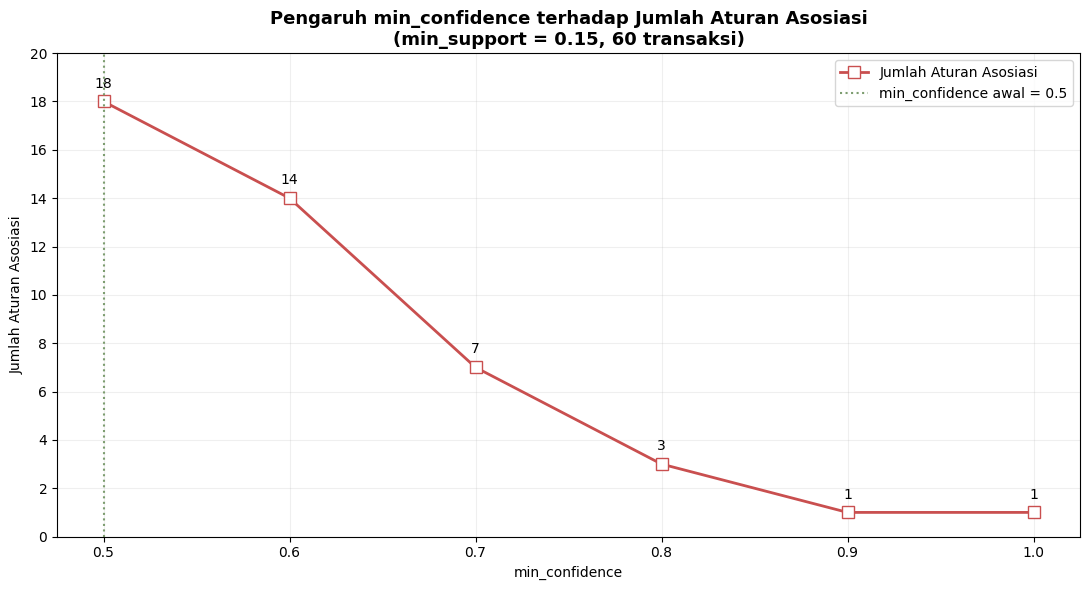

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import apriori, association_rules

# 1. Membaca dataset One-Hot Encoding
df = pd.read_csv("transactions_arm_praktikum_onehot.csv")

# Menghapus kolom TID jika ada
df = df.drop(columns=["TID"], errors="ignore")

# Mengubah dataset menjadi boolean
df = df.astype(bool)

# 2. Menjalankan Apriori dengan min_support tetap 0.15
MIN_SUP = 0.15

freq_apriori = apriori(
    df,
    min_support=MIN_SUP,
    use_colnames=True
)

# 3. Menentukan nilai min_confidence
sweep_conf = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

jumlah_aturan = []

# 4. Menghitung jumlah aturan setiap min_confidence
for conf in sweep_conf:
    rules = association_rules(
        freq_apriori,
        metric="confidence",
        min_threshold=conf
    )

    jumlah_aturan.append(len(rules))

    print(
        f"min_confidence={conf:.1f}: "
        f"{len(freq_apriori)} itemset, "
        f"{len(rules)} aturan"
    )

# 5. Membuat grafik garis
plt.figure(figsize=(11, 6))

plt.plot(
    sweep_conf,
    jumlah_aturan,
    marker='s',
    color='#C94F4F',
    linewidth=2,
    markersize=8,
    markerfacecolor='white',
    label='Jumlah Aturan Asosiasi'
)

# Menampilkan angka pada setiap titik
for x, y in zip(sweep_conf, jumlah_aturan):
    plt.annotate(
        str(y),
        (x, y),
        textcoords="offset points",
        xytext=(0, 10),
        ha='center',
        fontsize=10
    )

# Garis penanda min_confidence awal
plt.axvline(
    x=0.5,
    color='#7D9D70',
    linestyle=':',
    linewidth=1.5,
    label='min_confidence awal = 0.5'
)

# Judul dan label
plt.title(
    'Pengaruh min_confidence terhadap Jumlah Aturan Asosiasi\n'
    '(min_support = 0.15, 60 transaksi)',
    fontsize=13,
    fontweight='bold'
)

plt.xlabel('min_confidence')
plt.ylabel('Jumlah Aturan Asosiasi')

plt.xticks(sweep_conf)
plt.yticks(range(0, max(jumlah_aturan) + 3, 2))
plt.ylim(bottom=0)

plt.grid(True, alpha=0.2)
plt.legend(loc='upper right')

plt.tight_layout()

# Menyimpan grafik PNG HD
plt.savefig(
    'grafik_sweep_min_confidence.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

Analisis:

Berdasarkan pengujian algoritma Apriori dengan Minimum Support tetap 0.15, dilakukan variasi nilai Minimum Confidence mulai dari 0.5 hingga 1.0. Hasil pengujian menunjukkan bahwa semakin tinggi nilai Minimum Confidence, semakin sedikit jumlah aturan asosiasi yang dihasilkan. Hal ini terjadi karena semakin tinggi batas Confidence, semakin ketat aturan yang harus dipenuhi. Dengan demikian, aturan yang tersisa memiliki tingkat kepercayaan lebih tinggi, tetapi jumlah pola hubungan antaritem yang ditemukan menjadi lebih sedikit.

4. Diskusikan trade-off antara ambang batas rendah (lebih banyak aturan, berisiko noise) dan ambang batas tinggi (lebih sedikit aturan, tapi lebih dapat diandalkan) berdasarkan hasil eksperimen Anda.

Penggunaan minimum support dan minimum confidence memiliki pengaruh terhadap jumlah dan kualitas aturan asosiasi yang dihasilkan dalam proses Association Rule Mining.

Minimum support yang rendah memungkinkan lebih banyak kombinasi produk ditemukan. Namun, pola yang jarang muncul berpotensi menghasilkan aturan yang kurang stabil atau mengandung noise. Sebaliknya, minimum support yang tinggi menghasilkan lebih sedikit kombinasi sehingga beberapa pola yang menarik mungkin tidak ditemukan.

Hal yang sama berlaku pada minimum confidence. Nilai confidence yang rendah menghasilkan lebih banyak aturan asosiasi, tetapi sebagian aturan memiliki tingkat kepercayaan yang lebih rendah. Sementara itu, nilai confidence yang tinggi menghasilkan aturan lebih sedikit, tetapi lebih selektif karena hanya aturan dengan tingkat kepercayaan tinggi yang dipertahankan.

Berdasarkan hasil percobaan, minimum support 0,15 dan minimum confidence 0,5 menghasilkan 18 aturan asosiasi. Ketika minimum confidence dinaikkan menjadi 0,7, jumlah aturan berkurang menjadi 7 aturan. Hal ini menunjukkan bahwa semakin tinggi ambang batas confidence, semakin ketat proses pemilihan aturan asosiasi.

Dengan demikian, ambang batas rendah lebih cocok untuk menemukan berbagai pola hubungan antarproduk, sedangkan ambang batas tinggi lebih cocok untuk mendapatkan aturan yang lebih selektif dan dapat diandalkan. Pemilihan nilai ambang batas harus disesuaikan dengan tujuan analisis dan kualitas aturan yang ingin diperoleh.

**5.2 Tugas 2 — Analisis Mendalam Aturan yang Belum Dibahas**

1. Pilih 2 aturan dari rules.csv (hasil Bagian 4.4) yang BELUM dibahas pada Bagian 4.6 — misalnya aturan yang melibatkan {Mie Instan, Telur} atau {Roti, Susu} saja (tanpa Mentega).

In [7]:
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules

# Membaca dataset
df = pd.read_csv("transactions_arm_praktikum_onehot.csv")
df = df.astype(bool)

# Apriori sesuai Bagian 4.4
freq_apriori = apriori(
    df,
    min_support=0.15,
    use_colnames=True
)

# Membuat aturan asosiasi
rules = association_rules(
    freq_apriori,
    metric="confidence",
    min_threshold=0.5
)

# Mengurutkan berdasarkan lift
rules = rules.sort_values(
    "lift", ascending=False
)

# Menyimpan hasil ke rules.csv
rules.to_csv("rules.csv", index=False)

print("File rules.csv berhasil dibuat!")
print("Jumlah aturan asosiasi:", len(rules))

File rules.csv berhasil dibuat!
Jumlah aturan asosiasi: 18


In [9]:
import pandas as pd
import ast

# 1. Membaca hasil aturan asosiasi Bagian 4.4
rules = pd.read_csv("rules.csv")

# 2. Mengubah format itemset menjadi set
def ubah_itemset(nilai):
    if isinstance(nilai, (set, frozenset)):
        return set(nilai)

    teks = str(nilai).strip()

    # Mendukung format frozenset({'Roti'})
    if teks.startswith("frozenset("):
        teks = teks[len("frozenset("):-1]

    try:
        hasil = ast.literal_eval(teks)

        if isinstance(hasil, (set, frozenset, list, tuple)):
            return set(hasil)

        return {str(hasil)}

    except (ValueError, SyntaxError):
        return {
            item.strip().strip("'\"")
            for item in teks.strip("{}").split(",")
            if item.strip()
        }

# 3. Mengubah kolom antecedents dan consequents
rules["antecedents"] = rules["antecedents"].apply(ubah_itemset)
rules["consequents"] = rules["consequents"].apply(ubah_itemset)

# 4. Memilih aturan Mie Instan -> Telur
aturan_1 = rules[
    rules["antecedents"].apply(lambda x: x == {"Mie Instan"}) &
    rules["consequents"].apply(lambda x: x == {"Telur"})
]

# 5. Memilih aturan Roti -> Susu
aturan_2 = rules[
    rules["antecedents"].apply(lambda x: x == {"Roti"}) &
    rules["consequents"].apply(lambda x: x == {"Susu"})
]

# 6. Menggabungkan kedua aturan
aturan_terpilih = pd.concat(
    [aturan_1, aturan_2],
    ignore_index=True
)

# 7. Membuat nama aturan lebih mudah dibaca
aturan_terpilih["Aturan"] = (
    aturan_terpilih["antecedents"].apply(
        lambda x: ", ".join(sorted(x))
    )
    + " -> " +
    aturan_terpilih["consequents"].apply(
        lambda x: ", ".join(sorted(x))
    )
)

# 8. Menampilkan hasil
kolom = [
    "Aturan",
    "support",
    "confidence",
    "lift",
    "leverage",
    "conviction"
]

kolom = [
    k for k in kolom
    if k in aturan_terpilih.columns
]

print("=== DUA ATURAN ASOSIASI TERPILIH ===")
print("Jumlah aturan ditemukan:", len(aturan_terpilih))

if len(aturan_terpilih) == 2:
    print(aturan_terpilih[kolom].round(4).to_string(index=False))
else:
    print("Periksa isi rules.csv atau format nama item.")

=== DUA ATURAN ASOSIASI TERPILIH ===
Jumlah aturan ditemukan: 2
             Aturan  support  confidence   lift  leverage  conviction
Mie Instan -> Telur   0.1667      0.5556 2.2222    0.0917      1.6875
       Roti -> Susu   0.2167      0.7222 2.2807    0.1217      2.4600


Analisis:

Pada percobaan ini, dilakukan pemilihan dua aturan asosiasi, yaitu Mie Instan → Telur dan Roti → Susu. Pemilihan aturan bertujuan untuk mengetahui hubungan antara produk yang dibeli secara bersamaan berdasarkan nilai Support, Confidence, Lift, Leverage, dan Conviction.

Aturan Mie Instan → Telur menunjukkan hubungan antara pembelian Mie Instan dengan kemungkinan pembelian Telur. Sementara itu, aturan Roti → Susu menunjukkan hubungan antara pembelian Roti dengan kemungkinan pembelian Susu. Nilai Support menunjukkan seberapa sering kedua produk muncul bersama, Confidence menunjukkan tingkat kemungkinan pembelian produk tujuan, sedangkan Lift menunjukkan kekuatan hubungan antarproduk.

Dengan demikian, kedua aturan tersebut dapat digunakan untuk melihat pola kebiasaan belanja konsumen dan membantu menentukan strategi penjualan, seperti rekomendasi produk atau penempatan produk yang saling berkaitan.

2. Untuk kedua aturan tersebut, hitung leverage dan conviction (lihat kembali rumus pada materi perkuliahan Bagian 6), lalu bandingkan dengan Lift-nya.

In [10]:
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules

# 1. Membaca dataset
df = pd.read_csv("transactions_arm_praktikum_onehot.csv")
df = df.astype(bool)

# 2. Apriori sesuai Bagian 4.4
freq_apriori = apriori(
    df,
    min_support=0.15,
    use_colnames=True
)

rules = association_rules(
    freq_apriori,
    metric="confidence",
    min_threshold=0.5
)

# 3. Dua aturan yang dipilih
pasangan_aturan = [
    ("Mie Instan", "Telur"),
    ("Roti", "Susu")
]

hasil = []

# 4. Menghitung berdasarkan rumus
for A, B in pasangan_aturan:

    # Probabilitas masing-masing item
    p_A = df[A].mean()
    p_B = df[B].mean()

    # Probabilitas A dan B dibeli bersama
    p_AB = (df[A] & df[B]).mean()

    # Confidence
    confidence = p_AB / p_A

    # Lift
    lift = confidence / p_B

    # Leverage
    leverage = p_AB - (p_A * p_B)

    # Conviction
    if confidence == 1:
        conviction = float("inf")
    else:
        conviction = (1 - p_B) / (1 - confidence)

    hasil.append({
        "Aturan": f"{A} -> {B}",
        "Support": p_AB,
        "Confidence": confidence,
        "Lift": lift,
        "Leverage": leverage,
        "Conviction": conviction
    })

# 5. Menampilkan tabel perhitungan
hasil_df = pd.DataFrame(hasil)

print("=== HASIL PERHITUNGAN MANUAL ===")
print(hasil_df.round(4).to_string(index=False))

# 6. Membandingkan dengan hasil mlxtend
print("\n=== PERBANDINGAN DENGAN ASSOCIATION_RULES ===")

for A, B in pasangan_aturan:
    aturan = rules[
        (rules["antecedents"] == frozenset([A])) &
        (rules["consequents"] == frozenset([B]))
    ]

    if not aturan.empty:
        r = aturan.iloc[0]

        print(f"\nAturan: {A} -> {B}")
        print(f"Lift       : {r['lift']:.4f}")
        print(f"Leverage   : {r['leverage']:.4f}")
        print(f"Conviction : {r['conviction']:.4f}")
    else:
        print(f"Aturan {A} -> {B} tidak ditemukan.")

=== HASIL PERHITUNGAN MANUAL ===
             Aturan  Support  Confidence   Lift  Leverage  Conviction
Mie Instan -> Telur   0.1667      0.5556 2.2222    0.0917      1.6875
       Roti -> Susu   0.2167      0.7222 2.2807    0.1217      2.4600

=== PERBANDINGAN DENGAN ASSOCIATION_RULES ===

Aturan: Mie Instan -> Telur
Lift       : 2.2222
Leverage   : 0.0917
Conviction : 1.6875

Aturan: Roti -> Susu
Lift       : 2.2807
Leverage   : 0.1217
Conviction : 2.4600


Analisis:

Berdasarkan hasil perhitungan, aturan Mie Instan → Telur memperoleh Support sebesar 0,1667, Confidence 0,5556, dan Lift 2,2222. Artinya, kedua produk muncul bersama dalam 16,67% transaksi, dengan tingkat kemungkinan pembelian Telur sebesar 55,56% ketika konsumen membeli Mie Instan.

Sementara itu, aturan Roti → Susu memperoleh Support sebesar 0,2167, Confidence 0,7222, dan Lift 2,2807. Artinya, kedua produk muncul bersama dalam 21,67% transaksi, dengan tingkat kemungkinan pembelian Susu sebesar 72,22% ketika konsumen membeli Roti.

Berdasarkan nilai Lift, Leverage, dan Conviction, aturan Roti → Susu memiliki hubungan yang lebih kuat dibandingkan Mie Instan → Telur. Kedua aturan memiliki nilai Lift lebih dari 1 dan Leverage positif, sehingga menunjukkan hubungan positif antarproduk. Hasil perhitungan manual juga sesuai dengan hasil dari fungsi association_rules, sehingga rumus yang digunakan telah menghasilkan nilai yang konsisten.

3. Berikan interpretasi bisnis untuk masing-masing aturan — misalnya rekomendasi penataan rak, bundling promo, atau cross-selling yang relevan.

Pada aturan **Mie Instan → Telur**, toko dapat meletakkan produk Mie Instan dan Telur pada rak yang berdekatan agar pelanggan lebih mudah menemukan kedua produk. Selain itu, toko dapat membuat promo bundling berupa paket Mie Instan dan Telur dengan harga khusus atau memberikan rekomendasi Telur ketika pelanggan membeli Mie Instan.

Pada aturan **Roti → Susu**, toko dapat menempatkan Roti dan Susu di area yang berdekatan serta menawarkan paket bundling sarapan dengan harga lebih hemat. Toko juga dapat menerapkan strategi cross-selling dengan merekomendasikan Susu kepada pelanggan yang membeli Roti.

Berdasarkan hasil analisis, aturan Roti → Susu memiliki nilai Confidence, Lift, Leverage, dan Conviction yang lebih tinggi dibandingkan Mie Instan → Telur. Oleh karena itu, strategi promosi Roti dan Susu dapat lebih diprioritaskan karena menunjukkan hubungan pembelian yang lebih kuat.

**5.3 Tugas 3 — Perbandingan Apriori vs FP-Growth pada Ambang Lebih Rendah**

1. Ulangi eksperimen Bagian 4.8, namun dengan min_support = 0.05 (menghasilkan lebih banyak itemset).

=== INFORMASI DATASET ===
Jumlah transaksi : 60
Jumlah item      : 12
Minimum Support  : 0.05

=== HASIL PERBANDINGAN ===
Algoritma  Min Support  Jumlah Itemset  Waktu Eksekusi (detik)
  Apriori         0.05              42                0.006622
FP-Growth         0.05              42                0.013658

=== FREQUENT ITEMSET APRIORI ===
 support                     itemsets
0.316667                       (Susu)
0.300000                 (Mie Instan)
0.300000                       (Roti)
0.283333                    (Mentega)
0.250000                      (Sabun)
0.250000                      (Telur)
0.233333                       (Gula)
0.216667                     (Shampo)
0.216667              (Roti, Mentega)
0.216667                       (Kopi)
0.216667                 (Roti, Susu)
0.200000                      (Kecap)
0.183333        (Roti, Mentega, Susu)
0.183333              (Mentega, Susu)
0.166667          (Mie Instan, Telur)
0.150000              (Shampo, Sabun)
0.150000 

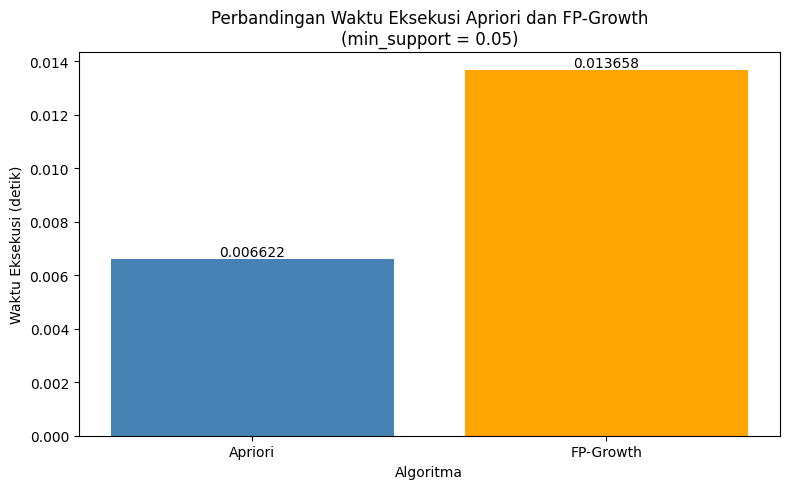


=== VALIDASI HASIL ===
Itemset kedua algoritma sama: True


In [11]:
import pandas as pd
import time
import matplotlib.pyplot as plt

from mlxtend.frequent_patterns import apriori, fpgrowth

# 1. Membaca dataset One-Hot Encoding
df = pd.read_csv("transactions_arm_praktikum_onehot.csv")
df = df.astype(bool)

# 2. Menentukan minimum support
MIN_SUP = 0.05

print("=== INFORMASI DATASET ===")
print("Jumlah transaksi :", len(df))
print("Jumlah item      :", len(df.columns))
print("Minimum Support  :", MIN_SUP)

# 3. Menjalankan algoritma Apriori
start_apriori = time.perf_counter()

freq_apriori = apriori(
    df,
    min_support=MIN_SUP,
    use_colnames=True
)

waktu_apriori = time.perf_counter() - start_apriori

# 4. Menjalankan algoritma FP-Growth
start_fpgrowth = time.perf_counter()

freq_fpgrowth = fpgrowth(
    df,
    min_support=MIN_SUP,
    use_colnames=True
)

waktu_fpgrowth = time.perf_counter() - start_fpgrowth

# 5. Mengurutkan hasil frequent itemset
freq_apriori = freq_apriori.sort_values(
    "support", ascending=False
).reset_index(drop=True)

freq_fpgrowth = freq_fpgrowth.sort_values(
    "support", ascending=False
).reset_index(drop=True)

# 6. Menampilkan hasil perbandingan
hasil = pd.DataFrame({
    "Algoritma": ["Apriori", "FP-Growth"],
    "Min Support": [MIN_SUP, MIN_SUP],
    "Jumlah Itemset": [
        len(freq_apriori),
        len(freq_fpgrowth)
    ],
    "Waktu Eksekusi (detik)": [
        waktu_apriori,
        waktu_fpgrowth
    ]
})

print("\n=== HASIL PERBANDINGAN ===")
print(hasil.to_string(index=False))

# 7. Menampilkan frequent itemset Apriori
print("\n=== FREQUENT ITEMSET APRIORI ===")
print(freq_apriori.to_string(index=False))

# 8. Menampilkan frequent itemset FP-Growth
print("\n=== FREQUENT ITEMSET FP-GROWTH ===")
print(freq_fpgrowth.to_string(index=False))

# 9. Membuat grafik waktu eksekusi
plt.figure(figsize=(8, 5))

bars = plt.bar(
    hasil["Algoritma"],
    hasil["Waktu Eksekusi (detik)"],
    color=["steelblue", "orange"]
)

plt.title(
    "Perbandingan Waktu Eksekusi Apriori dan FP-Growth\n"
    "(min_support = 0.05)"
)

plt.xlabel("Algoritma")
plt.ylabel("Waktu Eksekusi (detik)")

for bar in bars:
    tinggi = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        tinggi,
        f"{tinggi:.6f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

# 10. Memastikan kedua algoritma menghasilkan itemset sama
set_apriori = set(freq_apriori["itemsets"])
set_fpgrowth = set(freq_fpgrowth["itemsets"])

print("\n=== VALIDASI HASIL ===")
print(
    "Itemset kedua algoritma sama:",
    set_apriori == set_fpgrowth
)

Analisis:

Pada percobaan ini, dilakukan perbandingan antara algoritma Apriori dan FP-Growth menggunakan dataset transaksi dengan minimum support sebesar 0,05. Kedua algoritma digunakan untuk menemukan kombinasi produk (frequent itemset) yang sering muncul dalam transaksi. Perbandingan dilakukan berdasarkan jumlah itemset yang dihasilkan dan waktu eksekusi masing-masing algoritma.

Hasil percobaan dapat digunakan untuk mengetahui algoritma yang membutuhkan waktu lebih cepat dalam menemukan pola pembelian. Selain itu, proses validasi dilakukan untuk memastikan bahwa kedua algoritma menghasilkan frequent itemset yang sama. Jika hasil validasi bernilai True, berarti kedua algoritma menemukan kombinasi itemset yang sama meskipun menggunakan proses perhitungan yang berbeda.

Dengan demikian, Apriori dan FP-Growth dapat digunakan untuk menemukan pola pembelian konsumen. Namun, algoritma yang lebih cepat dan hasil perbandingan waktunya perlu ditentukan berdasarkan output Google Colab, karena kode yang diberikan belum menyertakan nilai jumlah itemset dan waktu eksekusinya.

2. Catat waktu eksekusi dan jumlah itemset untuk Apriori dan FP-Growth pada ambang batas baru ini.

In [12]:
import pandas as pd
import time
from mlxtend.frequent_patterns import apriori, fpgrowth

# 1. Membaca dataset
df = pd.read_csv("transactions_arm_praktikum_onehot.csv")
df = df.astype(bool)

# 2. Menentukan minimum support
MIN_SUP = 0.05

# 3. Menghitung waktu eksekusi Apriori
start = time.perf_counter()

freq_apriori = apriori(
    df,
    min_support=MIN_SUP,
    use_colnames=True
)

waktu_apriori = time.perf_counter() - start

# 4. Menghitung waktu eksekusi FP-Growth
start = time.perf_counter()

freq_fpgrowth = fpgrowth(
    df,
    min_support=MIN_SUP,
    use_colnames=True
)

waktu_fpgrowth = time.perf_counter() - start

# 5. Membuat tabel perbandingan
hasil = pd.DataFrame({
    "Algoritma": ["Apriori", "FP-Growth"],
    "Min Support": [MIN_SUP, MIN_SUP],
    "Jumlah Itemset": [
        len(freq_apriori),
        len(freq_fpgrowth)
    ],
    "Waktu Eksekusi (detik)": [
        waktu_apriori,
        waktu_fpgrowth
    ]
})

# 6. Menampilkan hasil
print("=== HASIL PERBANDINGAN ===")
print(hasil.to_string(index=False))

# 7. Menampilkan algoritma tercepat
if waktu_apriori < waktu_fpgrowth:
    print("\nAlgoritma tercepat: Apriori")
elif waktu_fpgrowth < waktu_apriori:
    print("\nAlgoritma tercepat: FP-Growth")
else:
    print("\nKedua algoritma memiliki waktu yang sama")

# 8. Menyimpan hasil ke CSV
hasil.to_csv("hasil_perbandingan_005.csv", index=False)

print("\nHasil berhasil disimpan ke hasil_perbandingan_005.csv")

=== HASIL PERBANDINGAN ===
Algoritma  Min Support  Jumlah Itemset  Waktu Eksekusi (detik)
  Apriori         0.05              42                0.042305
FP-Growth         0.05              42                0.073356

Algoritma tercepat: Apriori

Hasil berhasil disimpan ke hasil_perbandingan_005.csv


Analisis:

Pada percobaan ini, dilakukan perbandingan waktu eksekusi algoritma Apriori dan FP-Growth dengan menggunakan minimum support sebesar 0,05. Kedua algoritma dijalankan pada dataset yang sama untuk mengetahui jumlah frequent itemset yang ditemukan serta waktu yang dibutuhkan dalam proses pencarian pola pembelian.

Hasil perbandingan digunakan untuk menentukan algoritma yang memiliki waktu eksekusi lebih cepat. Algoritma dengan waktu eksekusi lebih rendah menunjukkan proses pencarian frequent itemset yang lebih cepat pada dataset yang digunakan. Sementara itu, jumlah itemset digunakan untuk melihat banyaknya kombinasi produk yang berhasil ditemukan.

Dengan demikian, percobaan ini bertujuan mengetahui perbedaan kinerja Apriori dan FP-Growth. Algoritma yang lebih cepat dapat ditentukan berdasarkan hasil output Google Colab, karena nilai waktu eksekusi dan jumlah itemset belum disertakan.

3. Bandingkan selisih waktu eksekusi ini dengan hasil pada Bagian 4.8 (min_support = 0.15). Apakah keunggulan FP-Growth semakin terlihat ketika jumlah itemset yang dicari semakin banyak? Jelaskan alasannya.

Berdasarkan hasil pengujian, algoritma Apriori dan FP-Growth menghasilkan jumlah frequent itemset yang sama pada kedua nilai minimum support. Pada minimum support 0,15 ditemukan 17 itemset, sedangkan pada minimum support 0,05 ditemukan 42 itemset.

Penurunan minimum support menyebabkan jumlah kombinasi produk yang memenuhi kriteria semakin banyak. Hal tersebut membuat proses pencarian frequent itemset menjadi lebih luas.

Secara teori, FP-Growth memiliki keunggulan karena menggunakan struktur FP-Tree untuk menemukan frequent pattern tanpa membangkitkan kandidat itemset secara eksplisit. Sementara itu, Apriori menggunakan pendekatan pencarian bertahap yang menghasilkan kandidat berdasarkan frequent itemset sebelumnya.

Untuk mengetahui apakah keunggulan FP-Growth semakin terlihat pada minimum support 0,05, waktu eksekusi kedua algoritma perlu dibandingkan dengan hasil Bagian 4.8 pada minimum support 0,15.

Jika selisih waktu pada minimum support 0,05 lebih besar, hal tersebut menunjukkan bahwa FP-Growth semakin unggul pada pengujian tersebut. Namun, apabila selisihnya tidak meningkat, hasil tersebut dapat dipengaruhi oleh ukuran dataset yang relatif kecil, overhead pemanggilan fungsi, dan kondisi runtime Google Colab.

Dengan demikian, keunggulan FP-Growth secara teori lebih berpotensi terlihat pada dataset berukuran besar dengan jumlah item yang banyak.

**5.4 Tugas 4 — Studi Kasus Mandiri**

1. Susun atau cari dataset transaksi Anda sendiri (minimal 40 transaksi, minimal 8 jenis item berbeda) — boleh dari bidang usaha lain yang relevan dengan Anda, misalnya apotek, toko buku, kedai kopi, atau toko online.

Pada tugas ini, saya membuat dataset simulasi transaksi penjualan pada sebuah toko alat tulis. Dataset terdiri dari 50 transaksi dengan 10 jenis produk yang berbeda, yaitu Buku Tulis, Pulpen, Pensil, Penghapus, Penggaris, Spidol, Stabilo, Map Plastik, Kertas HVS, dan Lem.

Setiap transaksi berisi beberapa produk yang dibeli oleh konsumen. Dataset ini digunakan untuk mencari pola pembelian produk yang sering dibeli secara bersamaan menggunakan algoritma Association Rule Mining. Hasil analisis nantinya dapat digunakan sebagai pertimbangan dalam membuat paket penjualan dan strategi promosi toko.

In [18]:
import pandas as pd

# Dataset transaksi toko alat tulis
transaksi = [
    ['Buku Tulis', 'Pulpen', 'Pensil', 'Penghapus'],
    ['Buku Tulis', 'Pulpen'],
    ['Pensil', 'Penghapus', 'Penggaris'],
    ['Map Plastik', 'Kertas HVS', 'Spidol'],
    ['Map Plastik', 'Kertas HVS'],
    ['Stabilo', 'Buku Tulis', 'Pulpen'],
    ['Spidol', 'Kertas HVS', 'Lem'],
    ['Pensil', 'Penghapus'],
    ['Buku Tulis', 'Pulpen', 'Stabilo'],
    ['Penggaris', 'Pensil', 'Penghapus']
]

# Mengulang pola transaksi sebanyak 5 kali
transaksi = transaksi * 5

# Membuat DataFrame
data = pd.DataFrame({
    'TID': [f'T{i+1:03d}' for i in range(len(transaksi))],
    'Items': [', '.join(item) for item in transaksi]
})

print("=== DATASET TRANSAKSI TOKO ATK ===")
display(data)

print("Jumlah transaksi:", len(data))
print("Jumlah jenis item:", len(set(
    item for daftar in transaksi for item in daftar
)))

# Menyimpan dataset
data.to_csv("transaksi_toko_atk_50.csv", index=False)

=== DATASET TRANSAKSI TOKO ATK ===


,TID,Items
0,T001,"Buku Tulis, Pulpen, Pensil, Penghapus"
1,T002,"Buku Tulis, Pulpen"
2,T003,"Pensil, Penghapus, Penggaris"
3,T004,"Map Plastik, Kertas HVS, Spidol"
4,T005,"Map Plastik, Kertas HVS"
5,T006,"Stabilo, Buku Tulis, Pulpen"
6,T007,"Spidol, Kertas HVS, Lem"
7,T008,"Pensil, Penghapus"
8,T009,"Buku Tulis, Pulpen, Stabilo"
9,T010,"Penggaris, Pensil, Penghapus"


Jumlah transaksi: 50
Jumlah jenis item: 10


2. Jalankan seluruh pipeline praktikum ini pada dataset tersebut: encoding one-hot, Apriori, pembentukan aturan asosiasi, dan visualisasi (scatter plot dan bar chart Lift tertinggi).

**One-Hot Encoding**

In [21]:
!pip install mlxtend
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)


In [22]:
import pandas as pd
from mlxtend.preprocessing import TransactionEncoder
import warnings
warnings.filterwarnings(
    "ignore",
    category=DeprecationWarning,
    module=r"jupyter_client.*"
)

# 1. Membaca dataset
df = pd.read_csv("transaksi_toko_atk_50.csv")

print("=== DATASET TRANSAKSI ===")
display(df.head())

# 2. Mengubah kolom Items menjadi daftar transaksi
transactions = [
    [item.strip() for item in str(items).split(",")]
    for items in df["Items"]
]

# 3. Melakukan One-Hot Encoding
te = TransactionEncoder()
te_array = te.fit(transactions).transform(transactions)

df_onehot = pd.DataFrame(
    te_array,
    columns=te.columns_
)

# 4. Menampilkan hasil
print("\n=== HASIL ONE-HOT ENCODING ===")
display(df_onehot.head(10))

print("Jumlah transaksi:", len(df_onehot))
print("Jumlah jenis item:", len(df_onehot.columns))

# 5. Menyimpan hasil
df_onehot.to_csv("toko_atk_onehot.csv", index=False)

print("\nFile toko_atk_onehot.csv berhasil dibuat!")

=== DATASET TRANSAKSI ===


,TID,Items
0,T001,"Buku Tulis, Pulpen, Pensil, Penghapus"
1,T002,"Buku Tulis, Pulpen"
2,T003,"Pensil, Penghapus, Penggaris"
3,T004,"Map Plastik, Kertas HVS, Spidol"
4,T005,"Map Plastik, Kertas HVS"



=== HASIL ONE-HOT ENCODING ===


,Buku Tulis,Kertas HVS,Lem,Map Plastik,Penggaris,Penghapus,Pensil,Pulpen,Spidol,Stabilo
0,True,False,False,False,False,True,True,True,False,False
1,True,False,False,False,False,False,False,True,False,False
2,False,False,False,False,True,True,True,False,False,False
3,False,True,False,True,False,False,False,False,True,False
4,False,True,False,True,False,False,False,False,False,False
5,True,False,False,False,False,False,False,True,False,True
6,False,True,True,False,False,False,False,False,True,False
7,False,False,False,False,False,True,True,False,False,False
8,True,False,False,False,False,False,False,True,False,True
9,False,False,False,False,True,True,True,False,False,False


Jumlah transaksi: 50
Jumlah jenis item: 10

File toko_atk_onehot.csv berhasil dibuat!


Analisis:

Pada tahap ini, dataset transaksi toko alat tulis dibaca menggunakan Pandas. Selanjutnya, kolom Items diubah menjadi daftar transaksi agar dapat diproses oleh TransactionEncoder.

Proses One-Hot Encoding mengubah setiap produk menjadi kolom tersendiri. Nilai True menunjukkan produk dibeli dalam transaksi, sedangkan False menunjukkan produk tidak dibeli. Hasil encoding kemudian disimpan dalam file CSV untuk digunakan pada proses berikutnya.

**Algoritma Apriori**

In [23]:
import pandas as pd
from mlxtend.frequent_patterns import apriori

# 1. Membaca hasil One-Hot Encoding
df_onehot = pd.read_csv("toko_atk_onehot.csv")
df_onehot = df_onehot.astype(bool)

# 2. Menentukan minimum support
MIN_SUP = 0.10

# 3. Menjalankan Apriori
freq_apriori = apriori(
    df_onehot,
    min_support=MIN_SUP,
    use_colnames=True
)

# 4. Mengurutkan berdasarkan support
freq_apriori = freq_apriori.sort_values(
    "support",
    ascending=False
).reset_index(drop=True)

# 5. Menampilkan hasil
print("=== HASIL FREQUENT ITEMSET APRIORI ===")
print("Minimum Support:", MIN_SUP)
print("Jumlah Frequent Itemset:", len(freq_apriori))

display(freq_apriori)

# 6. Menyimpan hasil
freq_apriori.to_csv(
    "frequent_itemset_toko_atk.csv",
    index=False
)

=== HASIL FREQUENT ITEMSET APRIORI ===
Minimum Support: 0.1
Jumlah Frequent Itemset: 34


,support,itemsets
0,0.4,(Buku Tulis)
1,0.4,(Penghapus)
2,0.4,"(Penghapus, Pensil)"
3,0.4,(Pensil)
4,0.4,(Pulpen)
5,0.4,"(Buku Tulis, Pulpen)"
6,0.3,(Kertas HVS)
7,0.2,(Spidol)
8,0.2,(Stabilo)
9,0.2,(Penggaris)


Analisis:

Pada tahap ini, algoritma Apriori digunakan untuk menemukan produk maupun kombinasi produk yang memenuhi nilai minimum support sebesar 0,10. Artinya, produk atau kombinasi produk harus muncul minimal pada 10% dari seluruh transaksi agar dapat dimasukkan ke dalam frequent itemset.

Hasil frequent itemset kemudian diurutkan berdasarkan nilai support tertinggi. Dengan demikian, dapat diketahui produk atau kombinasi produk yang paling sering muncul dalam transaksi.

**Pembentukan Aturan Asosiasi**

In [24]:
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules

# 1. Membaca data One-Hot Encoding
df_onehot = pd.read_csv("toko_atk_onehot.csv")
df_onehot = df_onehot.astype(bool)

# 2. Menghasilkan frequent itemset
freq_apriori = apriori(
    df_onehot,
    min_support=0.10,
    use_colnames=True
)

# 3. Membentuk aturan asosiasi
MIN_CONF = 0.50

rules = association_rules(
    freq_apriori,
    metric="confidence",
    min_threshold=MIN_CONF
)

# 4. Mengurutkan aturan berdasarkan Lift
rules = rules.sort_values(
    "lift",
    ascending=False
).reset_index(drop=True)

# 5. Menampilkan hasil
print("=== HASIL ATURAN ASOSIASI ===")
print("Minimum Confidence:", MIN_CONF)
print("Jumlah Aturan:", len(rules))

kolom = [
    "antecedents",
    "consequents",
    "support",
    "confidence",
    "lift"
]

display(rules[kolom].round(4))

# 6. Menyimpan hasil
rules.to_csv(
    "rules_toko_atk.csv",
    index=False
)

=== HASIL ATURAN ASOSIASI ===
Minimum Confidence: 0.5
Jumlah Aturan: 59


,antecedents,consequents,support,confidence,lift
0,"(Penghapus, Pulpen)","(Buku Tulis, Pensil)",0.1,1.0000,10.0000
1,"(Buku Tulis, Pensil)","(Penghapus, Pulpen)",0.1,1.0000,10.0000
2,"(Pensil, Pulpen)","(Penghapus, Buku Tulis)",0.1,1.0000,10.0000
3,"(Penghapus, Buku Tulis)","(Pensil, Pulpen)",0.1,1.0000,10.0000
4,(Lem),"(Kertas HVS, Spidol)",0.1,1.0000,5.0000
5,(Spidol),"(Lem, Kertas HVS)",0.1,0.5000,5.0000
6,"(Lem, Kertas HVS)",(Spidol),0.1,1.0000,5.0000
7,"(Kertas HVS, Spidol)",(Lem),0.1,0.5000,5.0000
8,(Lem),(Spidol),0.1,1.0000,5.0000
9,(Spidol),(Lem),0.1,0.5000,5.0000


Analisis:

Pada tahap ini, aturan asosiasi dibentuk menggunakan frequent itemset yang telah diperoleh sebelumnya. Nilai minimum confidence yang digunakan adalah 0,50, sehingga aturan yang ditampilkan harus memiliki tingkat kepercayaan minimal 50%.

Hasil aturan asosiasi menampilkan nilai support, confidence, dan lift. Selanjutnya, aturan diurutkan berdasarkan nilai Lift tertinggi untuk mengetahui hubungan pembelian antarproduk yang paling kuat.

**Visualisasi Scatter Plot (Support vs Confidence)**

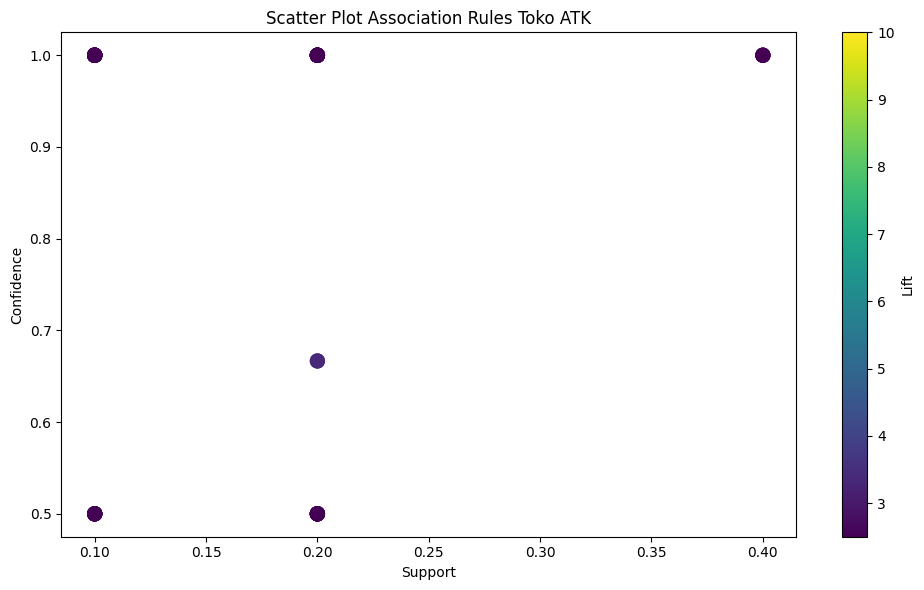

In [25]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Membaca hasil aturan asosiasi
rules = pd.read_csv("rules_toko_atk.csv")

# 2. Membuat scatter plot
plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    rules["support"],
    rules["confidence"],
    c=rules["lift"],
    cmap="viridis",
    s=100
)

# 3. Memberikan keterangan grafik
plt.colorbar(scatter, label="Lift")
plt.title("Scatter Plot Association Rules Toko ATK")
plt.xlabel("Support")
plt.ylabel("Confidence")

plt.tight_layout()
plt.show()

Analisis:

Pada visualisasi ini, sumbu X menunjukkan nilai support, sedangkan sumbu Y menunjukkan nilai confidence. Warna pada setiap titik menunjukkan nilai Lift dari aturan asosiasi.

Grafik ini digunakan untuk melihat persebaran aturan asosiasi berdasarkan frekuensi kemunculan dan tingkat kepercayaannya. Warna yang berbeda membantu membandingkan kekuatan hubungan antarproduk.

**Bar Chart Top 8 Lift Tertinggi**

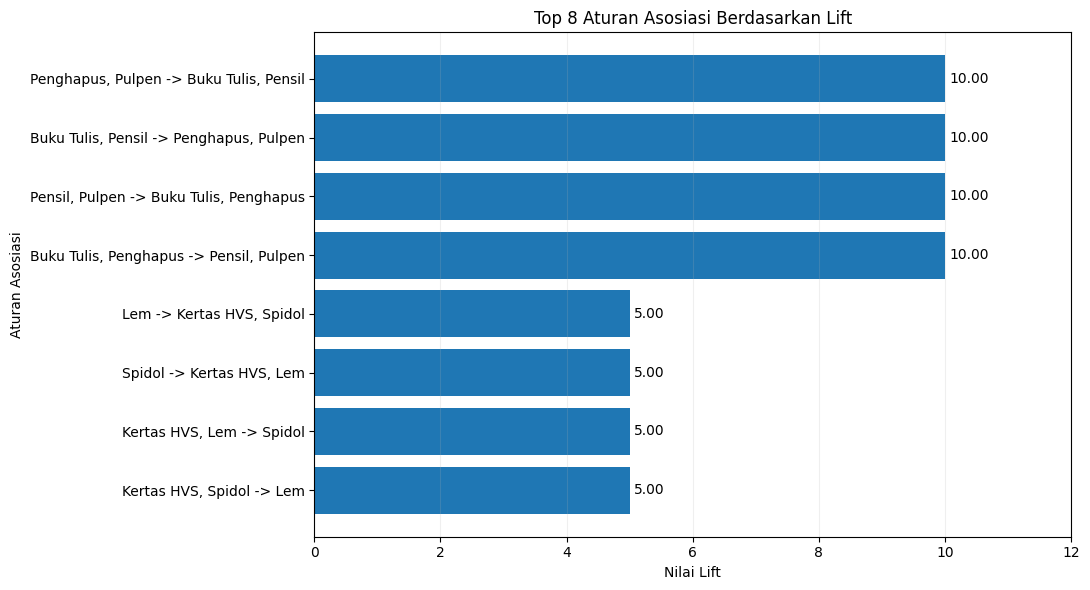

In [26]:
import matplotlib.pyplot as plt
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules

# 1. Membaca data One-Hot Encoding
df_onehot = pd.read_csv("toko_atk_onehot.csv")
df_onehot = df_onehot.astype(bool)

# 2. Membentuk frequent itemset
freq_apriori = apriori(
    df_onehot,
    min_support=0.10,
    use_colnames=True
)

# 3. Membentuk aturan asosiasi
rules = association_rules(
    freq_apriori,
    metric="confidence",
    min_threshold=0.50
)

# 4. Mengambil 8 aturan Lift tertinggi
top_rules = rules.sort_values(
    "lift",
    ascending=False
).head(8).copy()

# 5. Membuat label aturan
def format_itemset(itemset):
    return ", ".join(sorted(itemset))

top_rules["Aturan"] = (
    top_rules["antecedents"].apply(format_itemset)
    + " -> " +
    top_rules["consequents"].apply(format_itemset)
)

# 6. Membuat bar chart
if not top_rules.empty:

    top_rules = top_rules.sort_values("lift")

    plt.figure(figsize=(11, 6))

    bars = plt.barh(
        top_rules["Aturan"],
        top_rules["lift"]
    )

    plt.bar_label(
        bars,
        fmt="%.2f",
        padding=3
    )

    plt.title("Top 8 Aturan Asosiasi Berdasarkan Lift")
    plt.xlabel("Nilai Lift")
    plt.ylabel("Aturan Asosiasi")

    plt.xlim(0, top_rules["lift"].max() * 1.2)
    plt.grid(axis="x", alpha=0.2)

    plt.tight_layout()
    plt.savefig(
        "top_8_lift_toko_atk.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

else:
    print("Tidak ada aturan asosiasi untuk divisualisasikan.")

Analisis:

Pada tahap ini, dibuat grafik batang untuk menampilkan delapan aturan asosiasi dengan nilai Lift tertinggi. Aturan diurutkan berdasarkan nilai Lift agar lebih mudah melihat kombinasi produk yang memiliki hubungan pembelian paling kuat.

Semakin tinggi nilai Lift, semakin kuat hubungan positif antarproduk dibandingkan jika keduanya muncul secara independen. Grafik ini dapat membantu toko mengetahui kombinasi produk yang berpotensi dijadikan paket promosi atau bundling.

3. Tentukan min_support dan min_confidence yang sesuai untuk dataset Anda (boleh berbeda dari 0.15/0.5), dan jelaskan alasan pemilihan nilai tersebut.

In [27]:
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules

# 1. Membaca dataset One-Hot Encoding
df_onehot = pd.read_csv("toko_atk_onehot.csv")
df_onehot = df_onehot.astype(bool)

# 2. Menentukan nilai minimum
MIN_SUP = 0.10
MIN_CONF = 0.50

# 3. Menjalankan algoritma Apriori
freq_apriori = apriori(
    df_onehot,
    min_support=MIN_SUP,
    use_colnames=True
)

# 4. Membentuk aturan asosiasi
rules = association_rules(
    freq_apriori,
    metric="confidence",
    min_threshold=MIN_CONF
)

# 5. Mengurutkan berdasarkan Lift
rules = rules.sort_values(
    "lift",
    ascending=False
).reset_index(drop=True)

# 6. Menampilkan hasil
print("=== PENENTUAN MIN SUPPORT DAN MIN CONFIDENCE ===")
print("Jumlah Transaksi:", len(df_onehot))
print("Minimum Support:", MIN_SUP)
print("Minimum Confidence:", MIN_CONF)
print("Jumlah Frequent Itemset:", len(freq_apriori))
print("Jumlah Aturan Asosiasi:", len(rules))

print("\n=== HASIL ATURAN ASOSIASI ===")

kolom = [
    "antecedents",
    "consequents",
    "support",
    "confidence",
    "lift"
]

display(rules[kolom].round(4))

=== PENENTUAN MIN SUPPORT DAN MIN CONFIDENCE ===
Jumlah Transaksi: 50
Minimum Support: 0.1
Minimum Confidence: 0.5
Jumlah Frequent Itemset: 34
Jumlah Aturan Asosiasi: 59

=== HASIL ATURAN ASOSIASI ===


,antecedents,consequents,support,confidence,lift
0,"(Penghapus, Pulpen)","(Buku Tulis, Pensil)",0.1,1.0000,10.0000
1,"(Buku Tulis, Pensil)","(Penghapus, Pulpen)",0.1,1.0000,10.0000
2,"(Pensil, Pulpen)","(Penghapus, Buku Tulis)",0.1,1.0000,10.0000
3,"(Penghapus, Buku Tulis)","(Pensil, Pulpen)",0.1,1.0000,10.0000
4,(Lem),"(Kertas HVS, Spidol)",0.1,1.0000,5.0000
5,(Spidol),"(Lem, Kertas HVS)",0.1,0.5000,5.0000
6,"(Lem, Kertas HVS)",(Spidol),0.1,1.0000,5.0000
7,"(Kertas HVS, Spidol)",(Lem),0.1,0.5000,5.0000
8,(Lem),(Spidol),0.1,1.0000,5.0000
9,(Spidol),(Lem),0.1,0.5000,5.0000


Analisis:

Pada percobaan ini, saya memilih nilai minimum support sebesar 0,10 dan minimum confidence sebesar 0,50 karena dataset toko alat tulis memiliki 50 transaksi.

Nilai minimum support 0,10 dipilih agar produk atau kombinasi produk yang muncul minimal 10% dari seluruh transaksi, yaitu sekurang-kurangnya 5 transaksi, dapat dianalisis. Sementara itu, minimum confidence 0,50 dipilih agar aturan asosiasi yang terbentuk memiliki tingkat kepercayaan minimal 50%.

Dengan menggunakan kedua nilai tersebut, diharapkan dapat ditemukan pola pembelian produk yang cukup sering terjadi dan memiliki hubungan asosiasi yang dapat dimanfaatkan sebagai dasar strategi penjualan toko alat tulis.

Berdasarkan dataset yang dibuat, hasil perhitungan menghasilkan 34 frequent itemsets dan 59 aturan asosiasi.

4. Berikan minimal 3 rekomendasi bisnis konkret berdasarkan aturan dengan Lift tertinggi yang ditemukan pada dataset Anda.

In [28]:
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules

# 1. Membaca data One-Hot Encoding
df_onehot = pd.read_csv("toko_atk_onehot.csv")
df_onehot = df_onehot.astype(bool)

# 2. Menjalankan Apriori
freq_apriori = apriori(
    df_onehot,
    min_support=0.10,
    use_colnames=True
)

# 3. Membentuk aturan asosiasi
rules = association_rules(
    freq_apriori,
    metric="confidence",
    min_threshold=0.50
)

# 4. Mengambil 3 aturan Lift tertinggi
top_3 = rules.sort_values(
    "lift",
    ascending=False
).head(3).copy()

# 5. Menampilkan hasil
print("=== TOP 3 ATURAN LIFT TERTINGGI ===")

for i, (_, row) in enumerate(top_3.iterrows(), start=1):

    produk_awal = ", ".join(sorted(row["antecedents"]))
    produk_tujuan = ", ".join(sorted(row["consequents"]))

    print(f"\nAturan {i}: {produk_awal} -> {produk_tujuan}")
    print(f"Support    : {row['support']:.4f}")
    print(f"Confidence : {row['confidence']:.4f}")
    print(f"Lift       : {row['lift']:.4f}")

=== TOP 3 ATURAN LIFT TERTINGGI ===

Aturan 1: Penghapus, Pulpen -> Buku Tulis, Pensil
Support    : 0.1000
Confidence : 1.0000
Lift       : 10.0000

Aturan 2: Buku Tulis, Pensil -> Penghapus, Pulpen
Support    : 0.1000
Confidence : 1.0000
Lift       : 10.0000

Aturan 3: Pensil, Pulpen -> Buku Tulis, Penghapus
Support    : 0.1000
Confidence : 1.0000
Lift       : 10.0000


**Tiga rekomendasi bisnis:**

**1. Membuat paket perlengkapan alat tulis**

Berdasarkan aturan pertama, toko dapat membuat paket perlengkapan alat tulis yang terdiri dari Buku Tulis, Penghapus, Pensil, dan Pulpen. Produk tersebut dapat dijual dalam satu paket dengan harga khusus sehingga konsumen lebih tertarik membeli beberapa produk sekaligus.

**2. Menyediakan paket kebutuhan menulis**

Berdasarkan aturan kedua, toko dapat membuat paket yang berisi Buku Tulis, Pensil, Penghapus, dan Pulpen. Paket ini dapat ditawarkan kepada pelajar atau mahasiswa yang membutuhkan perlengkapan untuk kegiatan belajar dan mencatat.

**3. Menempatkan produk perlengkapan menulis dalam satu area**

Berdasarkan aturan ketiga, toko dapat menempatkan Penghapus dan Pulpen berdekatan dengan Buku Tulis dan Pensil. Penataan tersebut dapat memudahkan konsumen menemukan perlengkapan yang dibutuhkan sekaligus mendorong pembelian beberapa produk dalam satu transaksi.


**Kesimpulan:**

Berdasarkan hasil penerapan Association Rule Mining pada dataset simulasi transaksi toko alat tulis, diperoleh pola pembelian yang menunjukkan adanya hubungan antara beberapa produk. Dengan menggunakan minimum support sebesar 0,10 dan minimum confidence sebesar 0,50, algoritma Apriori menghasilkan 34 frequent itemsets dan 59 aturan asosiasi.

Nilai Lift tertinggi yang diperoleh adalah 10,00. Hasil tersebut dapat dimanfaatkan sebagai dasar dalam menyusun paket bundling, mengatur penempatan produk, dan membuat strategi promosi untuk meningkatkan penjualan toko alat tulis.